In [1]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack



In [2]:

import sys  
sys.path.insert(1, '\\\\smb.physics.wisc.edu\\smb\\friesen-group\\archives\\avivrekar\\Topological qubit\\Codes\\Spin_Splitting_Ge_ABS')

import Minimal_model_1D_1sub as M_1sub
import Minimal_Model_1D as M

In [3]:

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [4]:
NSM = 300          # in nm
NSC = 2000         # in nm
N = 2*NSC + NSM
AX = 1
#ALPHAT = 20        # meV-nm
DELTA = 1.65      # in meV
MEFF = 0.023       
PHI = 0.5*np.pi 
MU_const = 1.2
LY = 100
OMEGA = 2*4*hbm/LY**2/MEFF
print(OMEGA)


1.3263440267269595


In [5]:

ALPHAT = np.linspace(1, 100, 81)

K = 12

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M_1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF,  MU_const, phi=PHI)
    
    #print('done')

    Hli = Fli.H_sys()

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)


0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


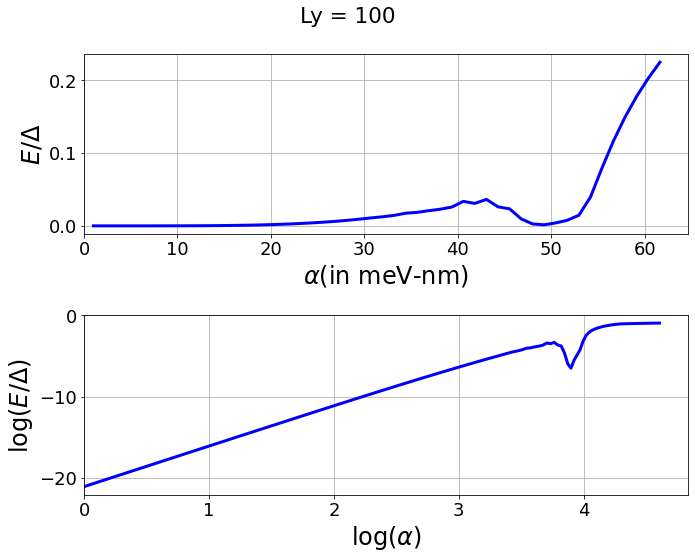

In [6]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT[:50]), (Ep_Split_li[:50]/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [7]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

ALPHAT = np.linspace(1, 100, 81)


K = 12

Ep_li2 = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li2[i,:] = Eli
    
    if i%5==0:
        print(i)


first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


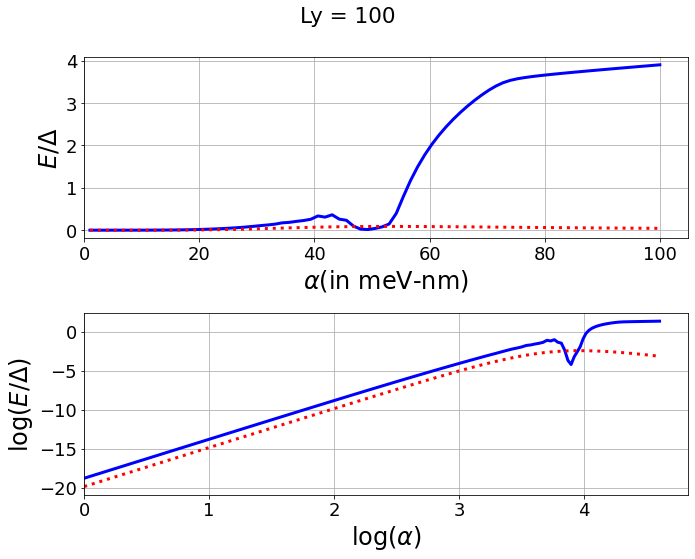

In [8]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li2 = Ep_li2[:,K//2+1] - Ep_li2[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot((ALPHAT), (Ep_Split_li2/DELTA), lw=3 ,linestyle =':' , color='red')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li2/DELTA), lw=3 ,linestyle =':' , color='red')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

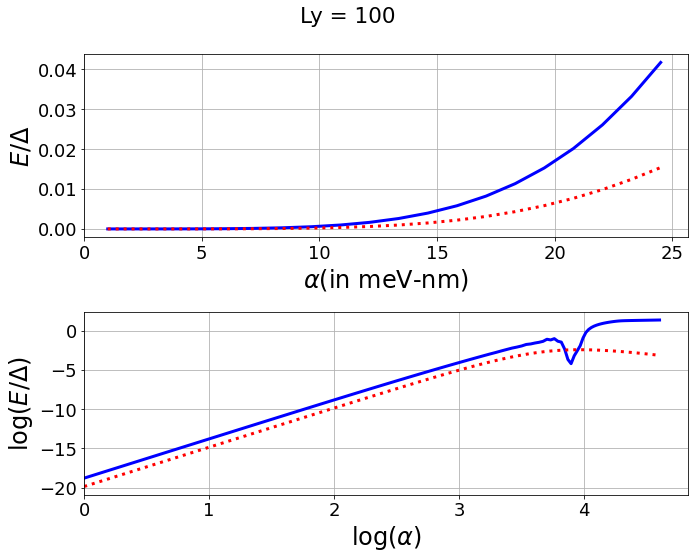

In [9]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li2 = Ep_li2[:,K//2+1] - Ep_li2[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT[:20]), (Ep_Split_li[:20]/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot((ALPHAT[:20]), (Ep_Split_li2[:20]/DELTA), lw=3 ,linestyle =':' , color='red')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li2/DELTA), lw=3 ,linestyle =':' , color='red')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [12]:
math.exp(3.5)

33.11545195869231

In [13]:
math.exp(1)

2.718281828459045

In [14]:
2.7**3

19.683000000000003

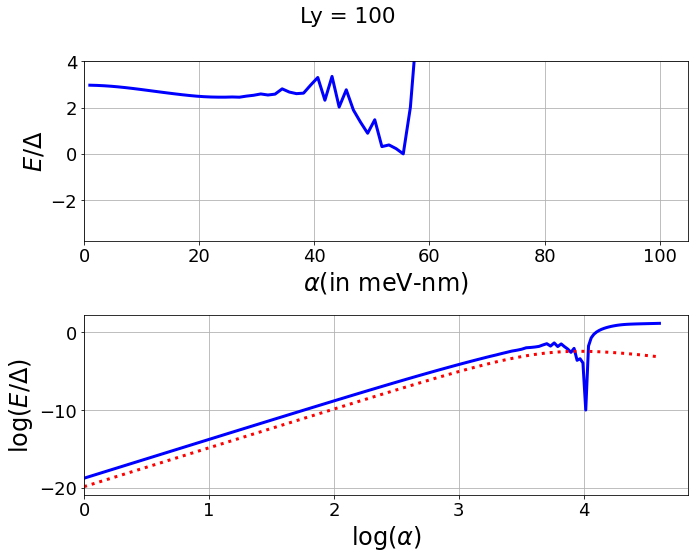

In [16]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li2 = Ep_li2[:,K//2+1] - Ep_li2[:,K//2]

Epd = np.divide(Ep_Split_li,Ep_Split_li2)

plt.subplot(2,1,1)
plt.plot((ALPHAT), (Epd), lw=3 ,linestyle ='-' , color='blue')
plt.ylim(ymax=4)
#plt.plot((ALPHAT[:20]), (Ep_Split_li2[:20]/DELTA), lw=3 ,linestyle =':' , color='red')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li2/DELTA), lw=3 ,linestyle =':' , color='red')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [17]:
print(Epd[:1])

[2.96192264]
